<a href="https://colab.research.google.com/github/gaduhprakoso/PCVK_Ganjil2026/blob/main/Week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**TUGAS INDIVIDU**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

3. Membuat Global Threshold Secara Manual

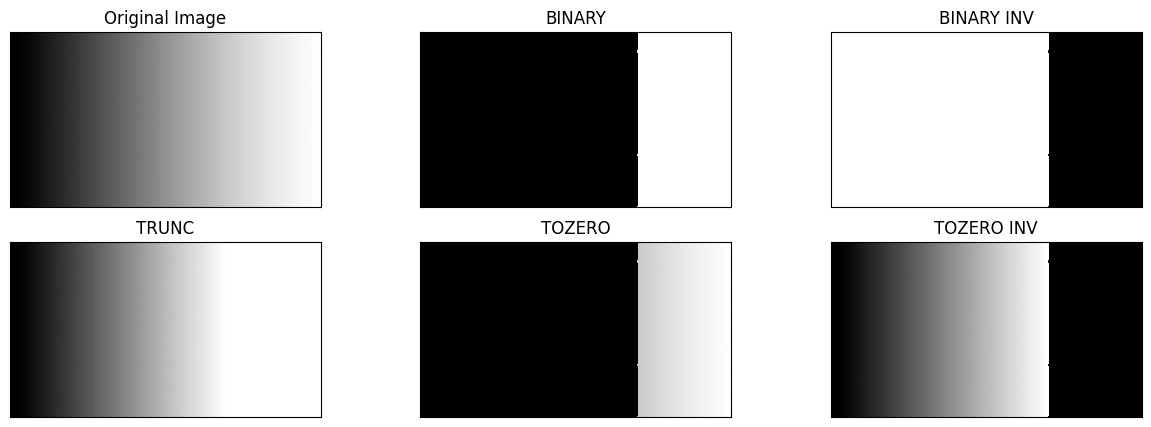

In [2]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt

filename = '/content/gradient.jpg'
img = cv.imread(filename, 0)
thresh = 200
maxval = 255

binary = np.zeros_like(img)
binary[img > thresh] = maxval

binary_inv = np.zeros_like(img)
binary_inv[img <= thresh] = maxval

trunc = img.copy()
trunc[img > thresh] = thresh

tozero = img.copy()
tozero[img <= thresh] = 0

tozero_inv = img.copy()
tozero_inv[img > thresh] = 0

# Visualisasi
titles = ['Original Image', 'BINARY', 'BINARY INV', 'TRUNC', 'TOZERO', 'TOZERO INV']
images = [img, binary, binary_inv, trunc, tozero, tozero_inv]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(2, 3, i + 1), plt.imshow(images[i], 'gray', interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

4. Membuat Adaptive Threshold (Mean & Gaussian) Secara Manual

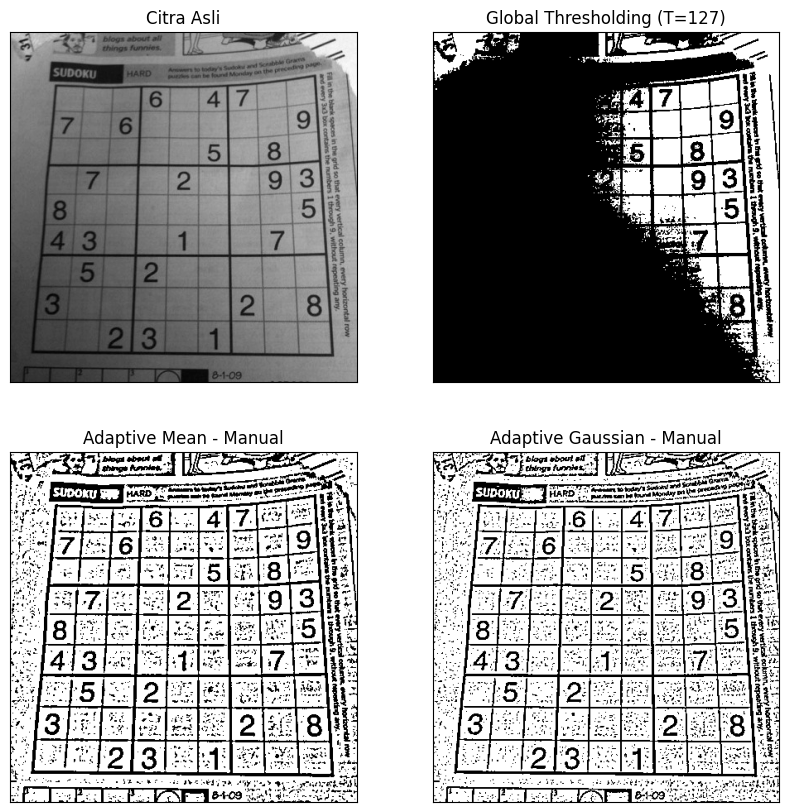

In [3]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

filename = '/content/sudoku-original.jpg'
img = cv.imread(filename, 0)

global_thresh = img.copy()
global_thresh[img > 127] = 255
global_thresh[img <= 127] = 0

def manual_adaptive_mean(image, block_size=11, C=2):
    pad_len = block_size // 2
    padded = np.pad(image, pad_len, mode='reflect')
    out = np.zeros_like(image)
    h, w = image.shape

    for y in range(h):
        for x in range(w):
            window = padded[y:y+block_size, x:x+block_size]
            mean_val = np.mean(window)
            if image[y, x] > (mean_val - C):
                out[y, x] = 255
            else:
                out[y, x] = 0
    return out

def manual_adaptive_gaussian(image, block_size=11, C=2, sigma=2):
    pad_len = block_size // 2
    padded = np.pad(image, pad_len, mode='reflect')
    out = np.zeros_like(image)
    h, w = image.shape

    ax = np.arange(-pad_len, pad_len + 1)
    xx, yy = np.meshgrid(ax, ax)
    kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    kernel = kernel / np.sum(kernel)

    for y in range(h):
        for x in range(w):
            window = padded[y:y+block_size, x:x+block_size]
            g_mean = np.sum(window * kernel)
            if image[y, x] > (g_mean - C):
                out[y, x] = 255
            else:
                out[y, x] = 0
    return out

th_mean = manual_adaptive_mean(img, block_size=11, C=2)
th_gauss = manual_adaptive_gaussian(img, block_size=11, C=2, sigma=2)

# Visualisasi
titles = ['Citra Asli', 'Global Thresholding (T=127)', 'Adaptive Mean - Manual', 'Adaptive Gaussian - Manual']
images = [img, global_thresh, th_mean, th_gauss]

plt.figure(figsize=(10, 10))
for i in range(len(images)):
    plt.subplot(2, 2, i + 1), plt.imshow(images[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

5. Otsu's Thresholding Tanpa Library & Analisis Citra Lena serta KTP

Optimal Threshold (Otsu): 93


/tmp/ipykernel_1272/420118973.py:53: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(blur.ravel(), 256, [0, 256])


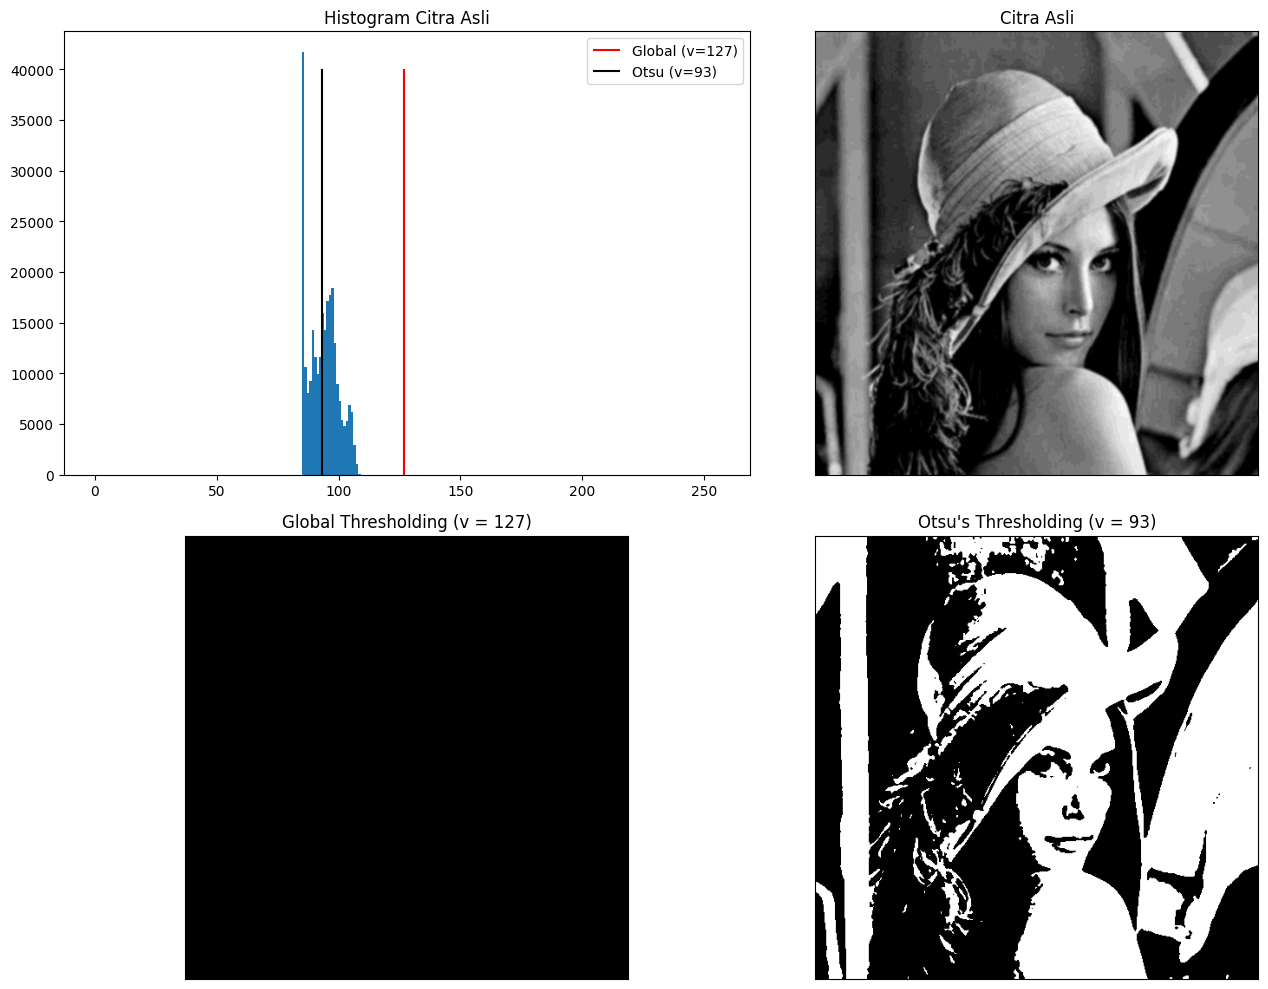

In [13]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

filename = '/content/lena_gs_lc2.jpg'
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0:
            continue
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight
        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = gray.copy()
    print(f"Optimal Threshold (Otsu): {final_thresh}")
    final_img[gray > final_thresh] = 255
    final_img[gray <= final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

x = f"Otsu's Thresholding (v = {otsu_thresh})"
titles = ['Citra Asli', f'Global Thresholding (v = {thresh})', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(14, 10))

# Plot Histogram Citra
plt.subplot(2, 2, 1)
plt.hist(blur.ravel(), 256, [0, 256])
plt.vlines(thresh, 0, 40000, colors='red', label=f'Global (v={thresh})')
plt.vlines(otsu_thresh, 0, 40000, colors='black', label=f'Otsu (v={otsu_thresh})')
plt.title('Histogram Citra Asli')
plt.legend()

for i in range(len(citra3)):
    plt.subplot(2, 2, i + 2)
    plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

Optimal Threshold (Otsu): 166


/tmp/ipykernel_1272/1376029963.py:50: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(blur.ravel(), 256, [0, 256])


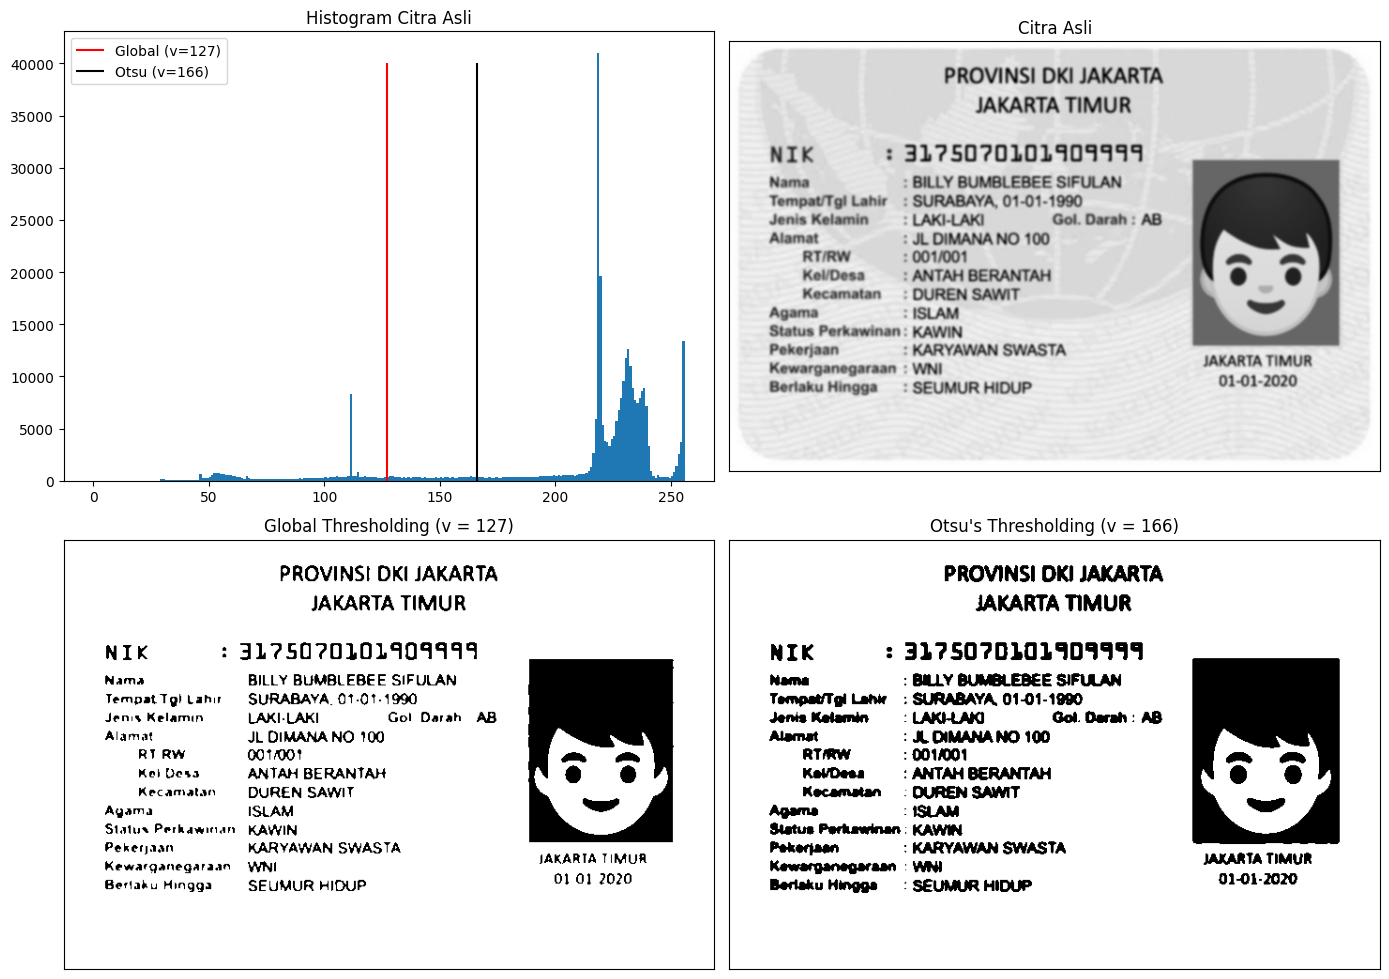

In [15]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

filename = '/content/ktp.jpg'
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0:
            continue
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight
        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = gray.copy()
    print(f"Optimal Threshold (Otsu): {final_thresh}")
    final_img[gray > final_thresh] = 255
    final_img[gray <= final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

x = f"Otsu's Thresholding (v = {otsu_thresh})"
titles = ['Citra Asli', f'Global Thresholding (v = {thresh})', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(14, 10))

# Plot Histogram Citra
plt.subplot(2, 2, 1)
plt.hist(blur.ravel(), 256, [0, 256])
plt.vlines(thresh, 0, 40000, colors='red', label=f'Global (v={thresh})')
plt.vlines(otsu_thresh, 0, 40000, colors='black', label=f'Otsu (v={otsu_thresh})')
plt.title('Histogram Citra Asli')
plt.legend()

for i in range(len(citra3)):
    plt.subplot(2, 2, i + 2)
    plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

**Penyebab**: Seluruh piksel citra Lena terkonsentrasi di bawah nilai $127$ (di kisaran 80–110), sedangkan garis threshold global berada di $127$. Karena semua piksel bernilai $\le 127$, aturan binary thresholding mengubahnya menjadi hitam penuh ($0$).  

**Solusi**: Nilai threshold harus diturunkan masuk ke dalam rentang histogram citra (sekitar angka $92$ atau hasil optimal Otsu) agar gambar Lena dapat terlihat.

6. Segmentasi Berbasis Region (skimage.data.coins dan flood)

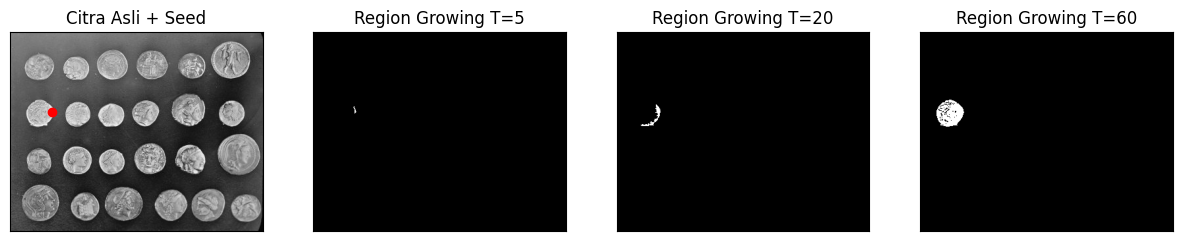

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.segmentation import flood

gray = data.coins()
seed = (121, 63)

region_t5 = flood(gray, seed_point=seed, tolerance=5, connectivity=1)
region_t20 = flood(gray, seed_point=seed, tolerance=20, connectivity=1)
region_t60 = flood(gray, seed_point=seed, tolerance=60, connectivity=1)

# Visualisasi hasil
fig, axes = plt.subplots(1, 4, figsize=(15, 5))
axes[0].imshow(gray, cmap='gray')
axes[0].plot(seed[1], seed[0], 'ro')
axes[0].set_title('Citra Asli + Seed')

axes[1].imshow(region_t5, cmap='gray')
axes[1].set_title('Region Growing T=5')

axes[2].imshow(region_t20, cmap='gray')
axes[2].set_title('Region Growing T=20')

axes[3].imshow(region_t60, cmap='gray')
axes[3].set_title('Region Growing T=60')

for ax in axes:
    ax.set_xticks([]), ax.set_yticks([])
plt.show()

7. Segmentasi Warna K-Means (Menampilkan Hanya Warna Biru pada KTP)

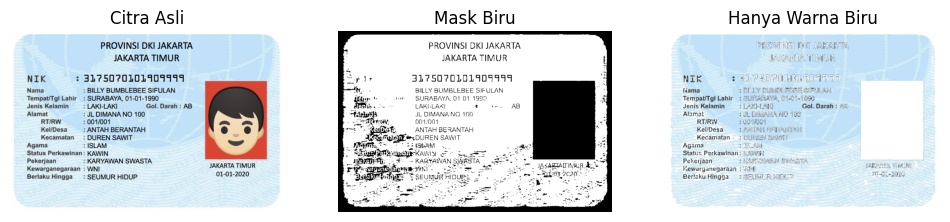

In [7]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

filename = '/content/ktp.jpg'
img_bgr = cv.imread(filename)
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_hsv = cv.cvtColor(img_bgr, cv.COLOR_BGR2HSV)

H = img_hsv[:, :, 0]
S = img_hsv[:, :, 1]
V = img_hsv[:, :, 2]

kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))
mask = np.zeros(img_rgb.shape[:2], dtype=np.uint8)
mask[kelompok_biru] = 255

biru = cv.bitwise_and(img_rgb, img_rgb, mask=mask)
biru[mask == 0] = [255, 255, 255]

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1), plt.imshow(img_rgb), plt.title('Citra Asli'), plt.axis('off')
plt.subplot(1, 3, 2), plt.imshow(mask, cmap='gray'), plt.title('Mask Biru'), plt.axis('off')
plt.subplot(1, 3, 3), plt.imshow(biru), plt.title('Hanya Warna Biru'), plt.axis('off')
plt.show()

**Tugas Kelompok**

In [16]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


In [17]:
import cv2
import pytesseract
from PIL import Image
import matplotlib.pyplot as plt

img_path = '/content/ktp.jpg'
img_color = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)

# Otsu Thresholding
_, img_otsu = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Adaptive Gaussian Thresholding
img_adaptive = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                     cv2.THRESH_BINARY, 11, 2)

# Konfigurasi Pytesseract bahasa Indonesia
custom_config = r'-l ind --psm 6'

text_color = pytesseract.image_to_string(img_rgb, config=custom_config)
text_otsu = pytesseract.image_to_string(img_otsu, config=custom_config)
text_adaptive = pytesseract.image_to_string(img_adaptive, config=custom_config)

print("--- OCR Citra Berwarna ---")
print(text_color[:300])
print("\n--- OCR Citra Otsu ---")
print(text_otsu[:300])
print("\n--- OCR Citra Adaptive ---")
print(text_adaptive[:300])

--- OCR Citra Berwarna ---
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 31750?0101901411
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW : 001/001

KellDesa —— : ANTAH BERANTAH N 4

Kecamatan  : DUREN SAWIT t
Agama : ISLAM
Status Per

--- OCR Citra Otsu ---
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 32?5D?0101401111
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin —: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW :001/001

KellDesa — : ANTAH BERANTAH

Kecamatan: DUREN SAWIT
Agama : ISLAM
Status Perkawinan:

--- OCR Citra Adaptive ---
sr (7 bg pr Ka it 3
“5 | PROVINSI DKI JAKARTA Eh 1
ea SSJAKARTA TIMUR | Ta!

Sm AN kt aah Bere IS
Pi Ae EA at Aha SE”
NIK Es Ah 250 2010) AON
Ta AA Ka AED Terate 2
Nama KA 4 BILLY BUMBLEBEE SIFULAN 3
ETempauTaI Lahir: :: SURABAYA, 01:01-1990—-adi.. «|
Jenis Kelamin 4—: LAKI-LAKI Gol, Darah AB F5 SS

